# Assignment 5: Wine Classification - Exploration, Visualization, and Modelling

In this assignment, I will load and explore the Wine dataset, visualize the relationships between its features, and build a Logistic Regression model to classify wines into three classes (class_0, class_1, class_2). Finally, I will evaluate the model using accuracy and a classification report.

The instructions ask for a regression analysis. Since the target is a category, I used Logistic Regression, which is a regression-based method used for classification.

## Step 1: Load and Explore the Dataset

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


In [2]:
pd.set_option("display.max_columns", None)


In [3]:
# Load the Wine dataset into a pandas DataFrame
wine = load_wine(as_frame=True)
wine_df = wine.frame

In [4]:
# Map target numbers (0, 1, 2) to class names
wine_df["target"] = wine_df["target"].map({0: "class_0", 1: "class_1", 2: "class_2"})

In [5]:
# First few rows
display(wine_df.head())


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [6]:
# Overview of the numeric features
display(wine_df.describe().round(2))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [7]:
# Number of wines in each class
print("Number of wines in each class:")
print(wine_df["target"].value_counts().sort_index())

Number of wines in each class:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


In [8]:
# Missing values
print("\nMissing values per column:")
print(wine_df.isnull().sum())
print("\nTotal missing values:", wine_df.isnull().sum().sum())


Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

Total missing values: 0


### Interpretation

I loaded the Wine dataset into a pandas DataFrame. It has 178 wines, 13 chemical features, and 1 target column.

I mapped the target numbers to their class names (0 to class_0, 1 to class_1, 2 to class_2), so the results and charts are easier to read.

From describe():
- All 13 features are numeric, but they are on very different scales. For example, proline ranges from about 278 to 1,680, while hue ranges from about 0.48 to 1.71. Because of this, I will scale the features before training the model.

Number of wines in each class:
- class_0: 59 wines
- class_1: 71 wines
- class_2: 48 wines
The classes are fairly balanced, so I do not need special techniques for imbalanced data.

Missing values:
Every column has 0 missing values, so no rows need to be removed or filled in. If there had been missing values, I would handle them after splitting the data, using only the training set to calculate fill values (such as the mean), to avoid data leakage.

## Step 2: Split the Data

In [9]:
X = wine_df.drop("target", axis=1)
y = wine_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nClass counts in training set:")
print(y_train.value_counts().sort_index())
print("\nClass counts in test set:")
print(y_test.value_counts().sort_index())

Training set: (142, 13)
Test set: (36, 13)

Class counts in training set:
target
class_0    47
class_1    57
class_2    38
Name: count, dtype: int64

Class counts in test set:
target
class_0    12
class_1    14
class_2    10
Name: count, dtype: int64


### Interpretation

I separated the 13 features (X) from the target (y), then split the data into 80% training and 20% testing using train_test_split with random_state=42.

- The training set has 142 wines and the test set has 36 wines, each with 13 features. 142 + 36 = 178, so no data was lost.
- I used stratify=y to keep the same class proportions in both sets.

Class counts:
- class_0: 47 in training (33.1%) and 12 in testing (33.3%)
- class_1: 57 in training (40.1%) and 14 in testing (38.9%)
- class_2: 38 in training (26.8%) and 10 in testing (27.8%)

The proportions are almost the same in both sets, so the test set fairly represents all three wine classes.

## Step 3: Data Visualization

### 3A: Pairplot of Key Features

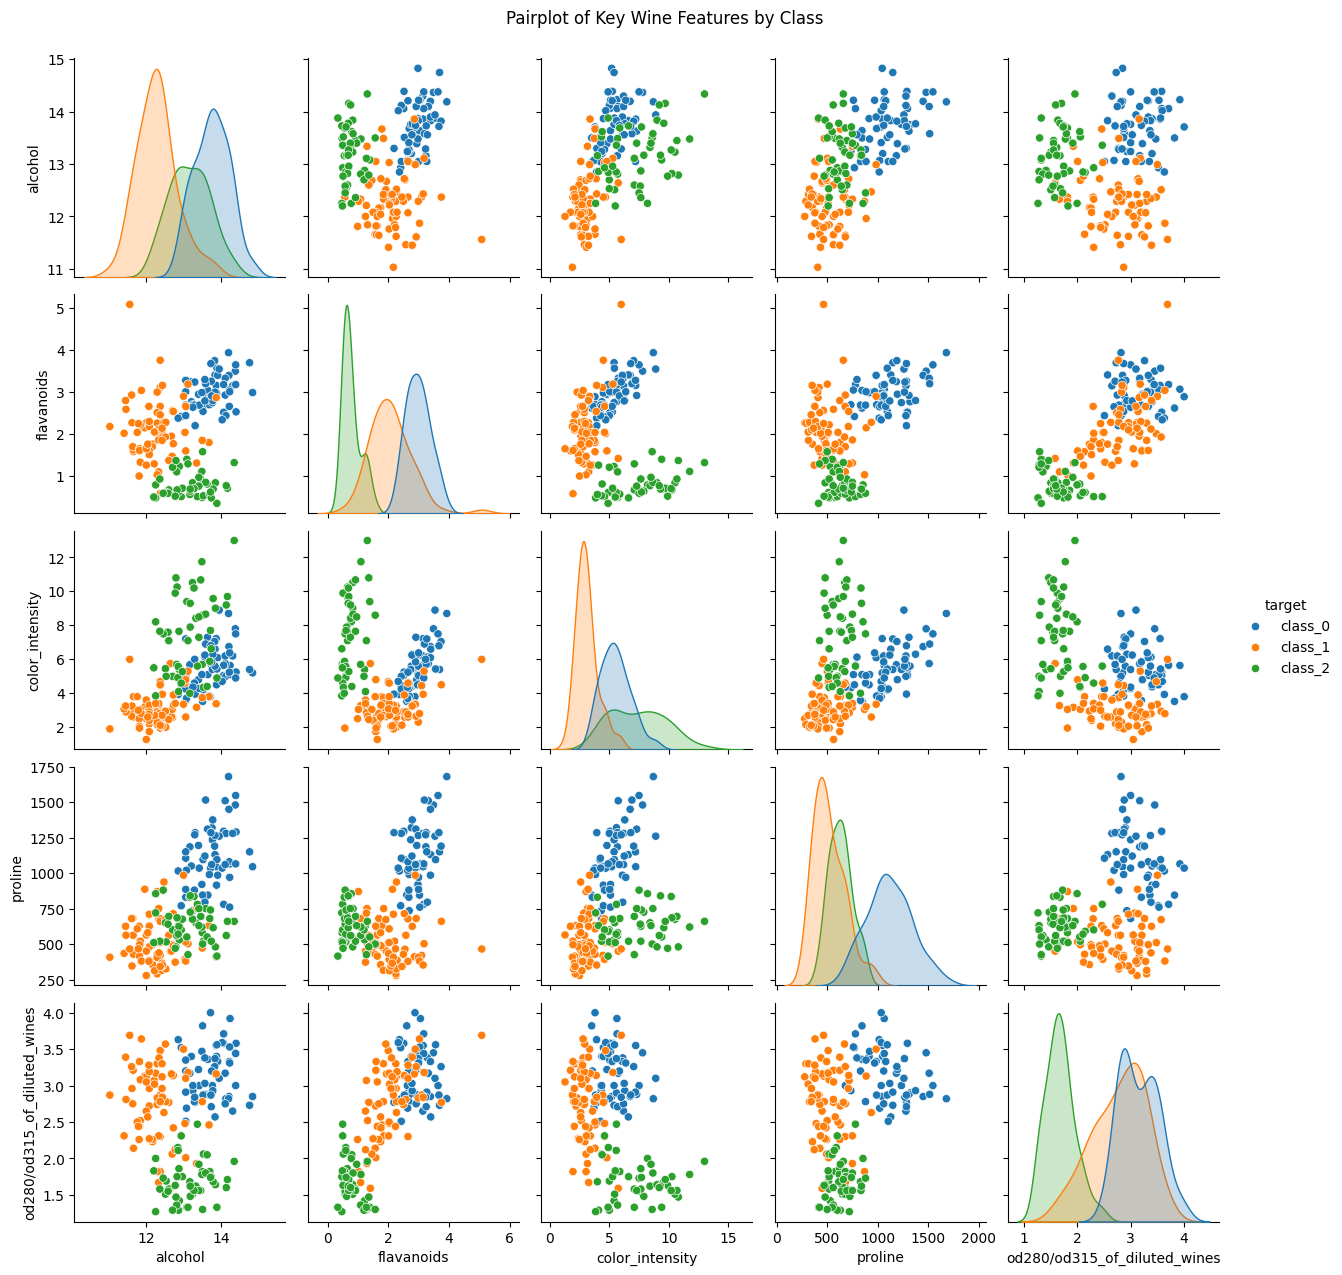

In [10]:
key_features = ["alcohol", "flavanoids", "color_intensity", "proline", "od280/od315_of_diluted_wines"]

sns.pairplot(wine_df[key_features + ["target"]], hue="target",
             hue_order=["class_0", "class_1", "class_2"], diag_kind="kde")
plt.suptitle("Pairplot of Key Wine Features by Class", y=1.02)
plt.show()

### Interpretation

The pairplot shows a scatter plot for every pair of the 5 selected features, with each wine coloured by its class (blue = class_0, orange = class_1, green = class_2). The charts on the diagonal show the distribution of each feature for each class. I used 5 key features instead of all 13, because a pairplot of all 13 features would create 169 small charts that would be too hard to read.

What each class looks like:
- class_0 (blue) has high alcohol, high flavanoids, and high proline.
- class_1 (orange) has low alcohol, low color intensity, and low proline.
- class_2 (green) has low flavanoids, high color intensity, and low od280/od315 values.

Features that separate the classes well (from the diagonal charts):
- Proline clearly separates class_0 from the other two classes, since class_0 has much higher proline.
- Flavanoids separates all three classes fairly well, with class_2 lowest, class_1 in the middle, and class_0 highest.
- Color intensity separates class_1 (low) from the others.
- od280/od315 separates class_2 (low) from the others.
- Alcohol separates class_1 (low) from class_0 (high), but class_2 overlaps with both.

Best feature pairs:
The scatter plots of flavanoids vs color intensity and flavanoids vs proline show three clearly separated groups. This suggests a classification model should be able to tell the wine classes apart very accurately.

Relationships between features:
Flavanoids and od280/od315 have a strong positive relationship. As one increases, the other also increases, so they carry similar information.

Outliers:
There is one class_1 wine with an unusually high flavanoids value (about 5), far to the right of all other wines. Most other points stay close to their class groups.

### 3B: Boxplot of Alcohol by Class

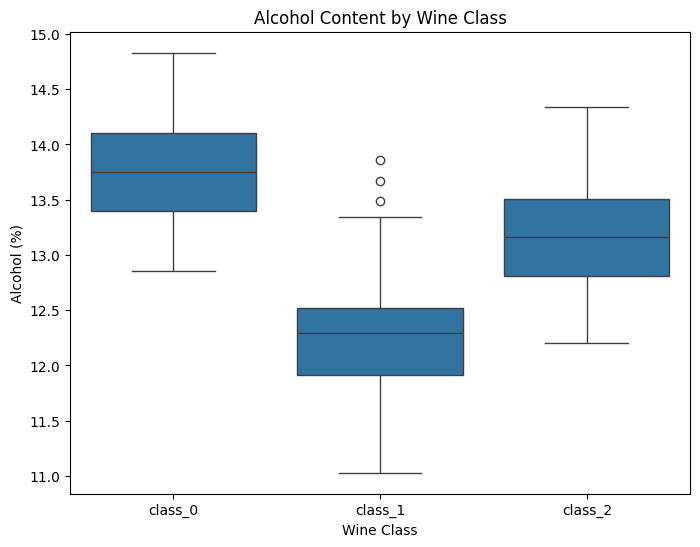

In [11]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=wine_df, x="target", y="alcohol",
            order=["class_0", "class_1", "class_2"])
plt.title("Alcohol Content by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol (%)")
plt.show()

### Interpretation

The boxplot shows the distribution of alcohol content for each wine class. The line inside each box is the median, the box covers the middle 50% of wines, the whiskers show the normal range, and the circles are outliers.

- class_0 has the highest alcohol content. Its median is about 13.75%, and most wines are between about 13.4% and 14.1%.
- class_1 has the lowest alcohol content. Its median is about 12.3%, and most wines are between about 11.9% and 12.5%. It also has the widest range, from about 11.0% to 13.35%.
- class_2 is in the middle, with a median of about 13.15%, and most wines are between about 12.8% and 13.5%.

Outliers:
class_1 has 3 outliers, at about 13.5%, 13.65%, and 13.85%. These wines have much higher alcohol than is normal for class_1, and are closer to the values of class_0 and class_2. No outliers appear in class_0 or class_2.

Overall, alcohol is a useful feature for separating class_1 from the other two classes. However, the boxes for class_0 and class_2 overlap in their ranges, so alcohol alone is not enough to tell those two classes apart. This is why the model needs to use all 13 features together.

## Step 4: Model Building

In [12]:
# Pipeline: scale the features, then Logistic Regression
log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=0.1, max_iter=1000, random_state=42))
])

# Train the model on the training data
log_reg.fit(X_train, y_train)

# Predict the classes of the test data
y_pred = log_reg.predict(X_test)

# Compare the first 10 predictions with the actual classes
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]
print(comparison.head(10))
print("\nCorrect predictions:", comparison["Correct"].sum(), "out of", len(comparison))

    Actual Predicted  Correct
0  class_0   class_0     True
1  class_2   class_2     True
2  class_0   class_0     True
3  class_1   class_1     True
4  class_1   class_1     True
5  class_0   class_0     True
6  class_0   class_0     True
7  class_1   class_1     True
8  class_1   class_1     True
9  class_2   class_2     True

Correct predictions: 36 out of 36


## Step 5: Model Evaluation

In [15]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



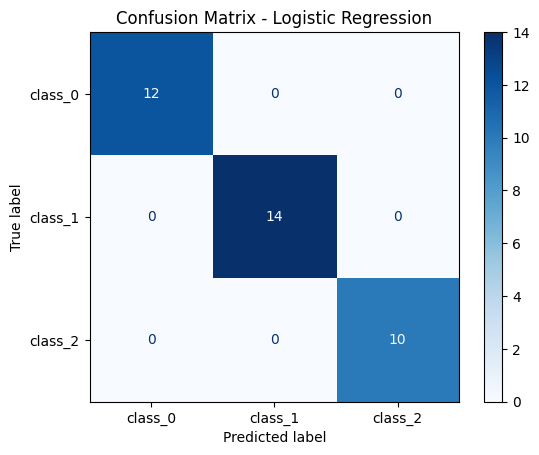

In [14]:
# Confusion matrix
class_names = ["class_0", "class_1", "class_2"]
cm = confusion_matrix(y_test, y_pred, labels=class_names)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

### Interpretation

Accuracy: The model reached an accuracy of 1.0 (100%), meaning all 36 test wines were classified correctly.

Classification report:
- Precision is 1.00 for all three classes. Every time the model predicted a class, it was correct, so there were no false positives.
- Recall is 1.00 for all three classes. The model found every wine of each class, so there were no false negatives.
- F1-score is 1.00 for all classes, because precision and recall are both perfect.
- Support shows the number of test wines in each class: 12 in class_0, 14 in class_1, and 10 in class_2.
- The macro average (simple average across the three classes) and the weighted average (average based on the number of wines in each class) are both 1.00.

Confusion matrix:
- The rows show the actual class and the columns show the predicted class.
- All the numbers are on the diagonal (12 for class_0, 14 for class_1, and 10 for class_2), and every other cell is 0. This means no wine was confused with another class.

Even though the result is perfect, the test set is small (36 wines), so one mistake would lower accuracy to about 97.2%. The visualizations showed that the three classes have very different chemical properties, which explains why the model separated them so well.

# Report: Model Accuracy and Performance

## Summary
In this assignment, I explored the Wine dataset, visualized the relationships between its features, and built a Logistic Regression model to classify wines into three classes. The model classified all 36 test wines correctly, with an accuracy of 100%.

## Data exploration
- The dataset has 178 wines, 13 chemical features, and 3 fairly balanced classes (59, 71, and 48 wines).
- There were no missing values, so no cleaning was needed.
- The features were on very different scales (for example, proline is in the hundreds or thousands while hue is below 2), so I scaled them before training.

## Visualization findings
- The pairplot showed that the three classes form clearly separate groups, especially when looking at flavanoids together with color intensity or proline.
- Each class has a clear chemical profile. class_0 has high alcohol, flavanoids, and proline. class_1 has low alcohol, color intensity, and proline. class_2 has low flavanoids and od280/od315 values and high color intensity.
- The alcohol boxplot showed that class_1 has much lower alcohol than the other two classes, while class_0 and class_2 overlap. This shows that no single feature is enough by itself, so the model needs all features together.
- I found a few outliers, such as one class_1 wine with very high flavanoids and three class_1 wines with unusually high alcohol.

## Model performance
- Model: Logistic Regression with C = 0.1, inside a Pipeline with StandardScaler
- Accuracy: 100% (36 out of 36 test wines correct)
- Precision, recall, and F1-score: 1.00 for all three classes
- Confusion matrix: no wines were misclassified

## Discussion
The model performed perfectly on the test set. This makes sense, because the visualizations already showed that the three classes have very different chemical properties and form clear groups. Logistic Regression works well when classes can be separated by mostly straight boundaries, which matches what I saw in the pairplot.

Scaling the features helped the model treat all features fairly, and using C = 0.1 (from my tuning in Assignment 4) added the right amount of regularization to prevent overfitting.

However, I should be careful about calling the model perfect. The test set has only 36 wines, so a single mistake would lower accuracy to about 97.2%. In Assignment 4, this same model had a cross-validation accuracy of 99.31%, which is likely a more realistic estimate of how it would perform on new wines. A larger dataset would give a more reliable evaluation.